In [132]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import gc
import math

import matplotlib.pyplot as plt
import seaborn as sns
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from utils import get_opt, get_loaders, eval_ppl

In [2]:
DEV = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

# Load

## Model

In [3]:
model_name = "HuggingFaceTB/SmolLM2-1.7B"

model = get_opt(model_name)
model.eval()
model.to(DEV)

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(49152, 2048)
    (layers): ModuleList(
      (0-23): 24 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (v_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (up_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=2048, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((2048,), eps=1e-05)
    (rotary_emb)

## Datasets

In [4]:
n_samples = 512
# n_samples = 256
# n_samples = 128

dataloader, testloader = get_loaders(
    "c4", nsamples=n_samples, seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (8597 > 8192). Running this sequence through the model will result in indexing errors


In [5]:
wiki_dataloader, wiki_testloader = get_loaders(
    'wikitext2', seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (2565857 > 8192). Running this sequence through the model will result in indexing errors


ts torch.Size([1, 2565857])


In [6]:
base_ppl = eval_ppl(model, testloader, device=DEV)
base_loss = float(np.log(base_ppl))
base_ppl, base_loss

(11.781546592712402, 2.4665344593096408)

# Utils

In [85]:
def visualize_dist(gate_store, ax=None):
    flat = torch.cat([t.reshape(-1) for t in gate_store])
    values = flat.float().detach().cpu().numpy()
    num_unique = len(np.unique(values))
    bins = min(100, num_unique)
    if ax is None: 
        plt.figure(figsize=(6, 3))
        plt.hist(values, bins=bins)
        plt.xlabel("Value")
        plt.ylabel("Count")
        plt.title("Distribution of decisions")
        plt.show()
    else:
        ax.hist(values, bins=bins)
        ax.set_xlabel("Value")
        ax.set_ylabel("Count")
        ax.set_title("Distribution of decisions")


# Architecture

In [8]:
class TokenGate(nn.Module):
    def __init__(self, d_model, noise_scale=0.0, tau=1.0):
        super().__init__()
        self.proj = nn.Linear(d_model, 1, dtype=torch.float32)
        self.noise_scale = noise_scale
        self.tau = tau

    def forward(self, h):
        logits = self.proj(h.to(torch.float32))              # [B, T, 1]

        if self.training and self.noise_scale > 0:
            u = torch.rand_like(logits).clamp(1e-6, 1-1e-6)
            noise = torch.log(u) - torch.log(1-u)        # logistic noise
            logits = logits + self.noise_scale * noise
        
        gate = torch.sigmoid(logits / self.tau)
        return gate


In [9]:
class GatedMLP(nn.Module):
    def __init__(self, mlp: nn.Module, d_model: int, gate_store: list,  noise_scale=0.0, tau=1.0):
        super().__init__()
        self.mlp = mlp
        self.gate = TokenGate(d_model, noise_scale=noise_scale, tau=tau)
        self.gate_store = gate_store      # to collect gates for loss
        self.active_gate = True

    def forward(self, h):
        if not self.active_gate:
            return self.mlp(h)
            
        g = self.gate(h)                  # [B, T, 1]
        self.gate_store.append(g)

        if self.training:            
            return g.to(h.dtype) * self.mlp(h)        # Standard continuous gating
        
        # --- Inference / Eval Mode Logic ---
        g_binary = (g > 0.5).to(h.dtype)
        g_flat = g_binary.view(-1)        # [B*T]
        h_flat = h.view(-1, h.size(-1))   # [B*T, D]
        active_indices = torch.where(g_flat > 0.5)[0]

        out_flat = torch.zeros_like(h_flat)
        if active_indices.numel() > 0:
            # only compute MLP for active tokens
            h_active = h_flat[active_indices]
            out_active = self.mlp(h_active)
            
            out_flat[active_indices] = out_active

        return out_flat.view(h.shape)

In [10]:
def deactivate_gates(model):
    for layer in model.model.layers:
        layer.mlp.active_gate = False 

def activate_gates(model):
    for layer in model.model.layers:
        layer.mlp.active_gate = True 

def add_gates(model, gate_store, noise_scale=0.0, tau=1.0):
    for layer in model.model.layers:
        d_model = layer.mlp.gate_proj.in_features
        layer.mlp = GatedMLP(layer.mlp, d_model, gate_store, noise_scale=noise_scale, tau=tau)

def set_noise(model, noise_scale=0.0):
    for layer in model.model.layers:
        layer.mlp.gate.noise_scale = noise_scale

def set_tau(model, tau=1.0):
    for layer in model.model.layers:
        layer.mlp.gate.tau = tau

In [11]:
def freeze_all_but_gates(model):
    for p in model.parameters():
        p.requires_grad = False
    for layer in model.model.layers:
        for p in layer.mlp.gate.parameters():   # TokenGate parameters
            p.requires_grad = True

def get_gate_params(model):
    weight_params = []
    bias_params = []
    for layer in model.model.layers:
        bias_params.append(layer.mlp.gate.proj.bias)
        weight_params.append(layer.mlp.gate.proj.weight)
    return weight_params, bias_params

def set_init_gate_weights(model, init_skip=0.3, w_std=1e-1):
    init_logit = math.log((1-init_skip) / init_skip)

    for layer in model.model.layers:
        gate = layer.mlp.gate.proj
        gate.bias.data.fill_(init_logit)
        gate.weight.data.normal_(0.0, w_std)
        

In [12]:
def kl_loss(student_logits, teacher_logits, T=1.0):
    # apply temperature
    student_log_probs = F.log_softmax(student_logits / T, dim=-1)
    teacher_probs = F.softmax(teacher_logits / T, dim=-1)

    loss = F.kl_div(
        student_log_probs,
        teacher_probs,
        reduction='batchmean'
    ) * (T ** 2)
    loss = loss / student_logits.size(1)  # divide by seq_len
    return loss

In [13]:
def gated_loss(lm_loss, gate_store,
               target_skip=0.3, lambda_ratio=1.0, lambda_bin=1.0):
    """
    lm_loss: scalar tensor
    gate_store: list of tensors [B, T, 1] (keep gates)
    """    
    # concatenate all gates -> [B*T*L]
    g = torch.cat([gi.reshape(-1) for gi in gate_store], dim=0)
    skip_ratio = (1.0 - g).mean()
    g_hard = torch.round(g.detach())
    skip_ratio_hard = (1.0 - g_hard).mean()

    # ratio loss (keep skip near target)
    ratio_loss = (skip_ratio - target_skip) ** 2

    # binarization loss (push gates to 0 or 1)
    bin_loss = (g * (1.0 - g)).mean()

    total_loss = lm_loss + lambda_ratio * ratio_loss + lambda_bin * bin_loss

    return total_loss, {
        "skip_ratio": skip_ratio,
        "skip_ratio_hard": skip_ratio_hard,
        "ratio_loss": ratio_loss.detach(),
        "bin_loss": bin_loss.detach(),
    }


In [14]:
def train_gates(model, dataloader, gate_store, stats, device="cuda",
                epochs=1, lrw=1e-4, lrb=1e-2,
                target_skip=0.30, lambda_ratio=1.0, lambda_bin=1.0,
                sigma_max=1, sigma_limit=0.7, tau_min=0.4, tau_limit=0.5,
                grad_accum_steps=1, max_grad_norm=1.0,
                verbose=False, eval_val_ppl=True, log_every=50):
    
    T = epochs * len(dataloader)

    # optimizer on gate params only
    weight_params, bias_params = get_gate_params(model)

    optimizer = torch.optim.AdamW([
        {"params": weight_params, "lr": lrw}, {"params": bias_params, "lr": lrb}
    ])
    
    scheduler = torch.optim.lr_scheduler.LinearLR(
        optimizer, start_factor=1.0, end_factor=0.001, total_iters=T
    )
    
    global_step = 0
    for epoch in range(epochs):
        for step, batch in enumerate(dataloader):
            global_step += 1
            gate_store.clear()

            input_ids, labels = batch
            batch = {"input_ids": input_ids.to(device), "labels": labels.to(device)}

            ##
            t = global_step / (T - 1)          # goes 0 -> 1
            
            tau   = 1.0 - (1.0 - tau_min) * min(1.0, t / tau_limit)    # 1 -> tau_min by (tau_limit*100) % of training
            sigma = sigma_max * (1.0 - min(1.0, t / sigma_limit))   # sigma_max -> 0 by (sigma_limit*100) % of training

            set_tau(model, tau)
            set_noise(model, sigma)
                        
            ##
            outputs = model(**batch)
            ppl = torch.exp(outputs.loss.detach()).item()
            # get original dense model outputs to calculate KL divergence
            with torch.no_grad():
                deactivate_gates(model)
                outputs_dense = model(**batch)
                activate_gates(model)
            
            lm_loss = kl_loss(outputs.logits, outputs_dense.logits)
            loss, loss_info = gated_loss(lm_loss, gate_store, lambda_ratio=lambda_ratio, lambda_bin=lambda_bin, target_skip=target_skip)
            loss = loss / grad_accum_steps
            loss.backward()

            if global_step % grad_accum_steps == 0:
                if max_grad_norm is not None:
                    torch.nn.utils.clip_grad_norm_(weight_params, max_grad_norm)
                    torch.nn.utils.clip_grad_norm_(bias_params, max_grad_norm)
                optimizer.step()
                optimizer.zero_grad(set_to_none=True)
                scheduler.step()

            # logging
            if (global_step == 1) or (global_step % log_every == 0):
                with torch.no_grad():
                    if verbose: visualize_dist(gate_store)
                    if eval_val_ppl:
                        model.eval()
                        val_ppl = eval_ppl(model, testloader, device=DEV)
                        model.train()
                    else: 
                        val_ppl = 0
                    lr = optimizer.param_groups[0]["lr"]
                    total_loss = lm_loss + lambda_ratio*loss_info['ratio_loss'] + lambda_bin*loss_info['bin_loss']
                    if verbose:
                        print(
                            f"{global_step:3} lr {lr:.1e} | "
                            # f"tau {tau:.2f} sigma {sigma:.2f} | "
                            f"ppl={ppl:6.2f} | val_ppl={val_ppl:6.2f} | "
                            f"skip_ratio={loss_info['skip_ratio'].item():.2f} | "
                            f"skip_ratio_h={loss_info['skip_ratio_hard'].item():.2f} | "
                            f"ratio_loss={(lambda_ratio*loss_info['ratio_loss']).item():.2f} | "
                            f"bin_loss={(lambda_bin*loss_info['bin_loss']).item():.2f} | "
                            f"kl_div={lm_loss.item():.2f} | "
                            f"total_loss={total_loss.item():.2f}"
                        )
                    stats['ppl'].append(ppl)
                    stats['val_ppl'].append(val_ppl)
                    stats['kl_div'].append(lm_loss.detach().cpu().item())
                    stats['skip_ratio'].append(loss_info['skip_ratio'].item())
                    stats['ratio_loss'].append((lambda_ratio*loss_info['ratio_loss']).item())
                    stats['bin_loss'].append((lambda_bin*loss_info['bin_loss']).item())
                    stats['total_loss'].append(total_loss.item())

    return model, stats

# Best model using different number of training samples

In [15]:
def train_best_hparams(n_samples, lrb, lrw, init_skip, target_skip):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    
    stats = {'ppl': [], 'val_ppl': [], 'kl_div': [], 'skip_ratio': [], 'ratio_loss': [], 'bin_loss': [], 'total_loss': []}

    model = get_opt(model_name)
    gate_store = []
    add_gates(model, gate_store=gate_store)
    model.to(DEV)
    model.train()
    
    set_init_gate_weights(model, init_skip=init_skip, w_std=1e-1)
    freeze_all_but_gates(model)
    
    model, stats = train_gates(
        model=model,
        dataloader=dataloader[:n_samples],
        gate_store=gate_store,
        stats=stats,
        device=DEV,
        epochs=1,
        lrw=lrw, lrb=lrb,
        sigma_max=0.5, sigma_limit=0.7, tau_min=0.4, tau_limit=0.5,
        target_skip=target_skip,
        lambda_ratio=1e2,
        lambda_bin=1,
        grad_accum_steps=1,
        log_every=16,
        verbose=True,
        eval_val_ppl=True
    )
    model.eval()
    return model, gate_store, stats

In [16]:
def plot_stats(stats):
    fig, ax = plt.subplots(2, 3, figsize=(10, 5))
    for i, x in enumerate(['ratio_loss', 'bin_loss', 'total_loss', 'ppl', 'skip_ratio', 'kl_div']): # ,'distribution']):
        r, c = divmod(i, 3)
        if x == 'distribution':
            flat = torch.cat([t.reshape(-1) for t in gate_store[-24:]])
            values = flat.float().detach().cpu().numpy()
            ax[r, c].hist(values, bins=100)
            ax[r, c].set_xlabel("Value")
            ax[r, c].set_ylabel("Count")
            ax[r, c].set_title(x)
            continue
        ax[r, c].plot(stats[x])
        ax[r, c].set_title(x)
        if x == 'ppl': 
            ax[r, c].plot(stats['val_ppl'])
            if (max(stats['ppl']) > 1e2) or (max(stats['val_ppl']) > 1e2):
                ax[r, c].set_ylim((-30, 100))
    fig.tight_layout(pad=2)

## 128

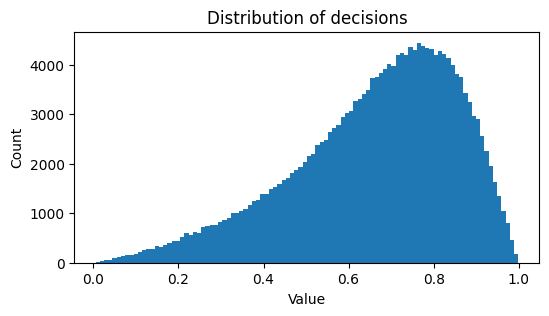

  1 lr 9.9e-03 | ppl=  8.17 | val_ppl= 24.01 | skip_ratio=0.34 | skip_ratio_h=0.20 | ratio_loss=0.14 | bin_loss=0.19 | kl_div=1.33 | total_loss=1.66


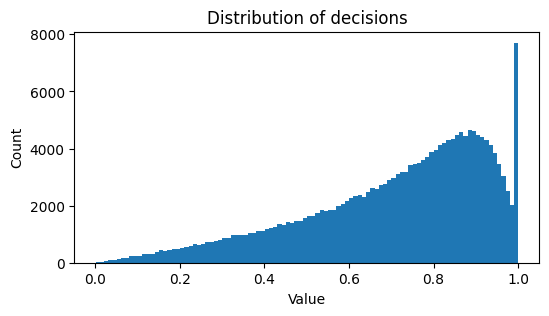

 16 lr 8.8e-03 | ppl=  9.02 | val_ppl= 13.70 | skip_ratio=0.29 | skip_ratio_h=0.18 | ratio_loss=0.01 | bin_loss=0.16 | kl_div=0.36 | total_loss=0.53


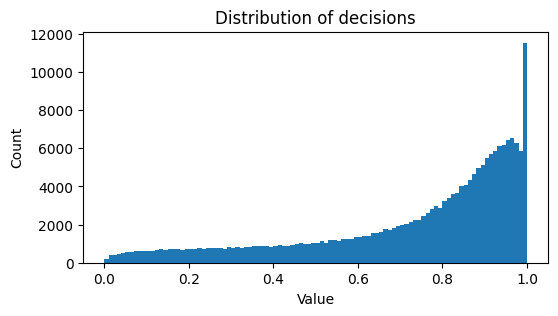

 32 lr 7.5e-03 | ppl=  1.05 | val_ppl= 14.22 | skip_ratio=0.27 | skip_ratio_h=0.19 | ratio_loss=0.10 | bin_loss=0.13 | kl_div=0.16 | total_loss=0.39


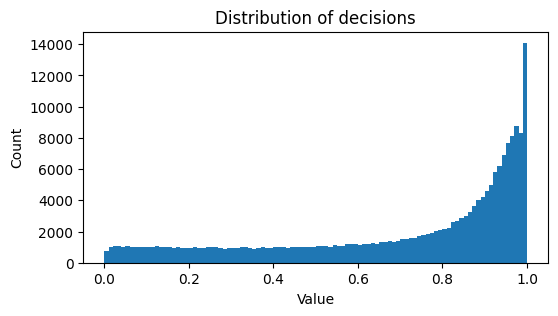

 48 lr 6.3e-03 | ppl=  2.17 | val_ppl= 15.19 | skip_ratio=0.29 | skip_ratio_h=0.25 | ratio_loss=0.00 | bin_loss=0.12 | kl_div=0.27 | total_loss=0.39


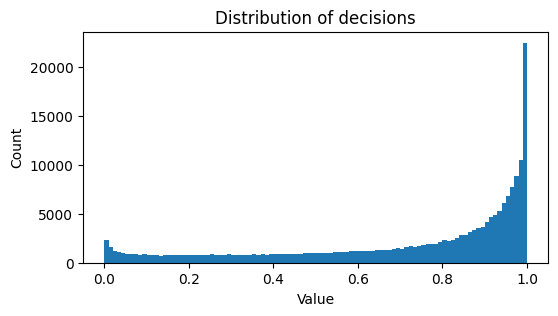

 64 lr 5.0e-03 | ppl=  6.12 | val_ppl= 17.38 | skip_ratio=0.28 | skip_ratio_h=0.23 | ratio_loss=0.04 | bin_loss=0.11 | kl_div=0.39 | total_loss=0.54


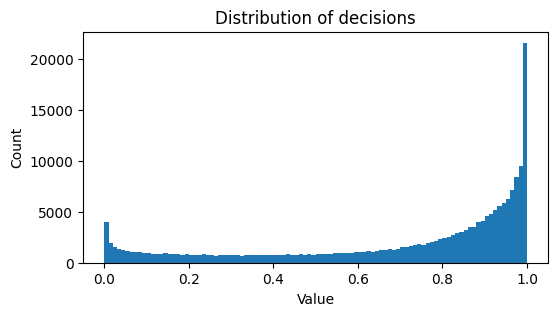

 80 lr 3.8e-03 | ppl= 12.35 | val_ppl= 19.93 | skip_ratio=0.29 | skip_ratio_h=0.24 | ratio_loss=0.01 | bin_loss=0.11 | kl_div=0.32 | total_loss=0.44


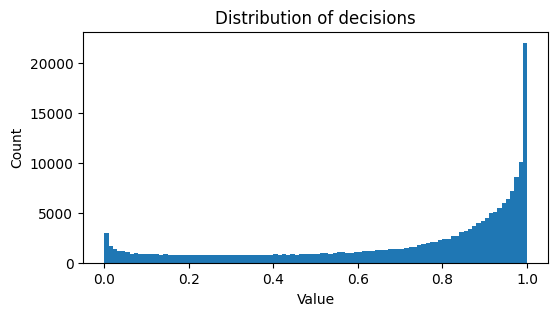

 96 lr 2.5e-03 | ppl=  1.02 | val_ppl= 19.18 | skip_ratio=0.28 | skip_ratio_h=0.23 | ratio_loss=0.04 | bin_loss=0.11 | kl_div=0.26 | total_loss=0.40


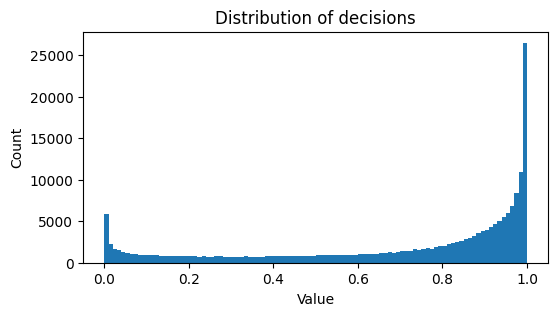

112 lr 1.3e-03 | ppl= 10.80 | val_ppl= 23.83 | skip_ratio=0.30 | skip_ratio_h=0.25 | ratio_loss=0.00 | bin_loss=0.10 | kl_div=0.32 | total_loss=0.43


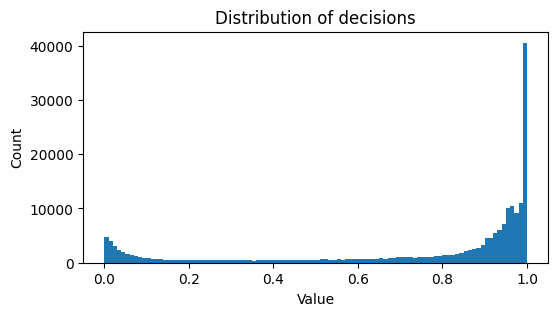

128 lr 1.0e-05 | ppl=  1.06 | val_ppl= 22.61 | skip_ratio=0.25 | skip_ratio_h=0.22 | ratio_loss=0.21 | bin_loss=0.08 | kl_div=0.22 | total_loss=0.51


In [17]:
model, gate_store, stats = train_best_hparams(n_samples=128, lrb=0.001, lrw=0.01, init_skip=0.3, target_skip=0.3)

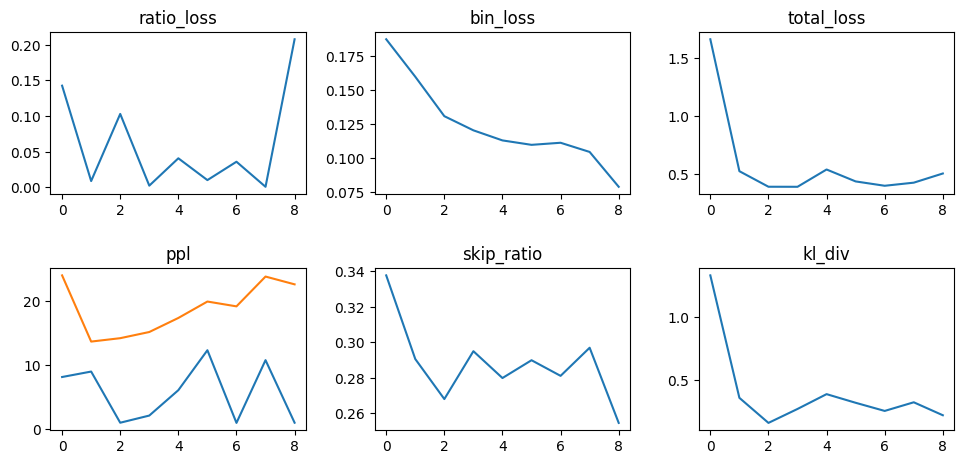

In [18]:
plot_stats(stats)

## Model Stats

In [17]:
def model_stats(n_samples, lrb, lrw, init_skip, target_skip):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    
    stats = {'ppl': [], 'val_ppl': [], 'kl_div': [], 'skip_ratio': [], 'ratio_loss': [], 'bin_loss': [], 'total_loss': []}

    model = get_opt(model_name)
    gate_store = []
    add_gates(model, gate_store=gate_store)
    model.to(DEV)
    model.train()
    
    set_init_gate_weights(model, init_skip=init_skip, w_std=1e-1)
    freeze_all_but_gates(model)
    
    model, stats = train_gates(
        model=model,
        dataloader=dataloader[:n_samples],
        gate_store=gate_store,
        stats=stats,
        device=DEV,
        epochs=1,
        lrw=lrw, lrb=lrb,
        sigma_max=0.5, sigma_limit=0.7, tau_min=0.4, tau_limit=0.5,
        target_skip=target_skip,
        lambda_ratio=1e2,
        lambda_bin=1,
        grad_accum_steps=1,
        log_every=16,
        verbose=False,
        eval_val_ppl=False
    )
    gate_store.clear()
    model.eval()
    val_ppl = eval_ppl(model, wiki_testloader, device=DEV)
    hard_skip_rate = 1-torch.Tensor([x.round().mean() for x in gate_store[-24:]]).mean().item()
    return val_ppl, hard_skip_rate, gate_store

In [18]:
csv_path = "results/model_stats_results.csv"

configs = [
    (128, 1, 1e-2, 0.3, 0.3),
    (128, 1e-2, 1e-2, 0.3, 0.3),
    (128, 1, 1e-2, 0.3, 0.4),
    (128, 1, 1e-2, 0.3, 0.5),
    (128, 1, 1e-2, 0.5, 0.5),

    (256, 1, 1e-2, 0.3, 0.3),
    (256, 0.1, 1e-2, 0.5, 0.3),
    (256, 1, 1e-2, 0.3, 0.4),
    (256, 1, 1e-2, 0.5, 0.5),

    (512, 1, 1e-2, 0.3, 0.3),
    (512, 1, 1e-2, 0.3, 0.4),
    (512, 1, 1e-2, 0.5, 0.5),
]

for run_id, (n_samples, lrb, lrw, init_skip, target_skip) in enumerate(configs):
    val_ppl, skip_rate, gate_store = model_stats(
        n_samples, lrb, lrw, init_skip, target_skip
    )

    # ---- save gate_store (binary, efficient) ----
    torch.save(
        [t.detach().cpu() for t in gate_store],
        f"results/gate_store_run_{run_id}.pt"
    )

    # ---- prepare one row for CSV ----
    row = pd.DataFrame([{
        "run_id": run_id,
        "n_samples": n_samples,
        "lrb": lrb,
        "lrw": lrw,
        "init_skip": init_skip,
        "target_skip": target_skip,
        "val_ppl": float(val_ppl),
        "skip_rate": float(skip_rate),
        "gate_store_file": f"results/gate_store_run_{run_id}.pt"
    }])

    # ---- append to CSV ----
    if not os.path.exists(csv_path):
        row.to_csv(csv_path, index=False)
    else:
        row.to_csv(csv_path, mode="a", header=False, index=False)

## Decision visualization

In [2]:
gate_results = pd.read_csv('results/model_stats_results.csv')
gate_results.query('skip_ratio>0.25 and skip_ratio<0.28')

,run_id,n_samples,lrb,lrw,init_skip,target_skip,val_ppl,skip_ratio
1,1,128,0.01,0.01,0.3,0.3,12.054555,0.264979
6,6,256,0.10,0.01,0.5,0.3,11.517119,0.257492
9,9,512,1.00,0.01,0.3,0.3,11.059547,0.256744


In [24]:
gate_decisions = {
    row['n_samples']: torch.load(f"results/gate_decisions/gate_store_run_{int(row['run_id'])}.pt")
    for i, row in gate_results.query('skip_ratio>0.25 and skip_ratio<0.28').iterrows()
}

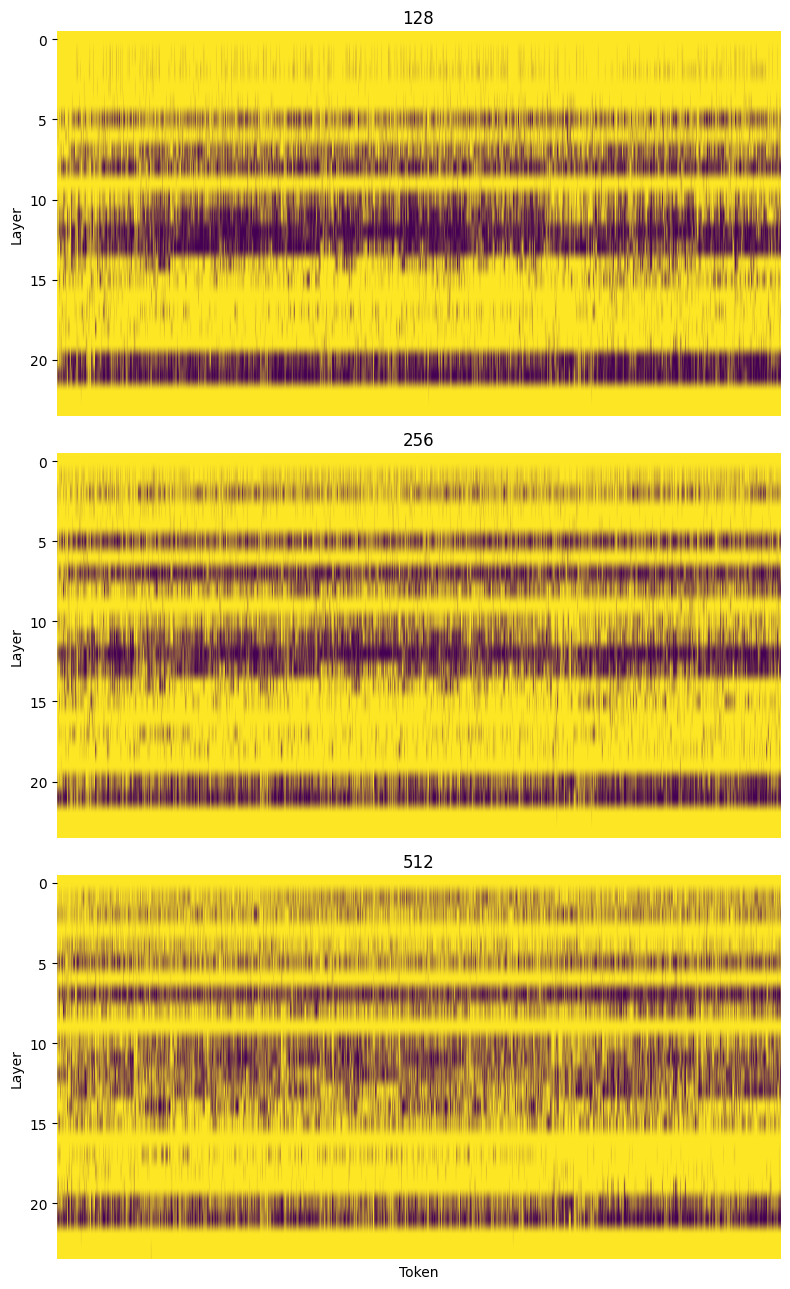

In [57]:
fig, axes = plt.subplots(3, 1, figsize=(8, 13))

models = [128, 256, 512]

for i, m in enumerate(models):
    ax = axes[i]

    data = torch.stack(
        [x.round() for x in gate_decisions[m][-24:]]
    ).squeeze().cpu().numpy()

    im = ax.imshow(data, aspect='auto', vmin=0, vmax=1)

    ax.set_title(str(m))
    ax.set_ylabel("Layer")

    if i == 2:
        ax.set_xlabel("Token")

    # keep only left spine + left ticks
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)

    ax.yaxis.set_ticks_position('left')
    ax.xaxis.set_ticks_position('none')  # or 'bottom' if you want x ticks

    ax.tick_params(axis='x', bottom=False, labelbottom=False)
plt.tight_layout()

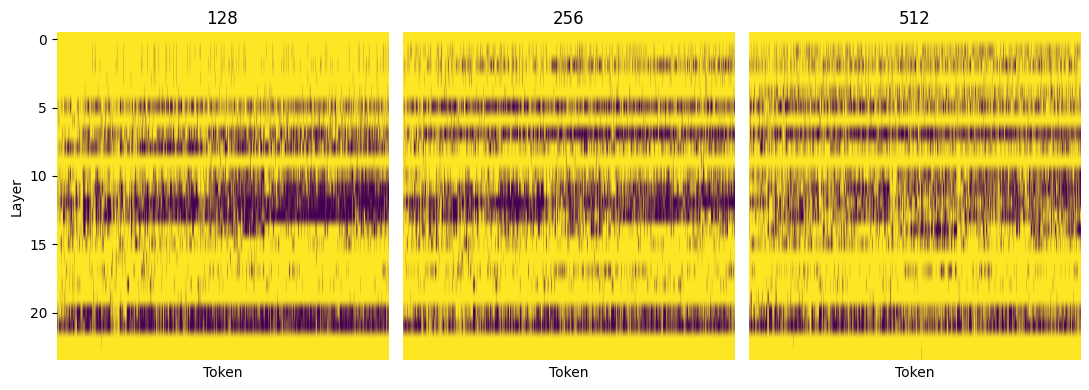

In [84]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4))

models = [128, 256, 512]

for i, m in enumerate(models):
    ax = axes[i]

    data = torch.stack(
        [x.round() for x in gate_decisions[m][-24:]]
    ).squeeze().cpu().numpy()[:, :2048]

    im = ax.imshow(data, aspect='auto', vmin=0, vmax=1)

    ax.set_title(str(m))
    ax.set_xlabel("Token")

    # --- spine + ticks logic ---
    if i == 0:
        ax.set_ylabel("Layer")
        ax.yaxis.set_ticks_position('left')
        ax.tick_params(axis='y', left=True, labelleft=True)
    else:
        ax.set_ylabel("")
        ax.tick_params(axis='y', left=False, labelleft=False)

    # remove everything else everywhere
    ax.spines['left'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['bottom'].set_visible(False)

    ax.tick_params(axis='x', bottom=False, labelbottom=False)

plt.tight_layout()

### Per-layer skip rate

In [88]:
len(gate_decisions[128])

888

In [91]:
888 /24

37.0

In [105]:
def reshape(values):
    arr = torch.stack(values).squeeze()
    arr = arr.reshape(37, 24, 8192)
    arr = arr.permute(1, 0, 2) 
    return arr.reshape(24, 37 * 8192)

In [114]:
layer_skip_ratios = {
    ns: reshape(gate_decisions[ns]).mean(axis=1) for ns in (128, 256, 512)
}
token_skip_ratios = {
    ns: reshape(gate_decisions[ns]).mean(axis=0) for ns in (128, 256, 512)
}

In [123]:
pd.DataFrame(layer_skip_ratios).to_csv('results/gates_layer_skip.csv')

In [124]:
pd.DataFrame(token_skip_ratios).to_csv('results/gates_token_skip.csv')

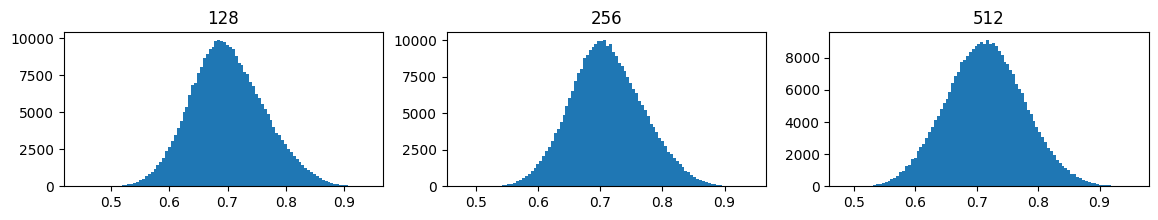

In [140]:
fig, axes = plt.subplots(1, 3, figsize=(14, 2))
for i, ns in enumerate((128, 256, 512)):
    axes[i].hist(token_skip_ratios[ns], bins=100)
    axes[i].set_title(ns)